# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zhang 2022's HGSOC malignant manifold is **non-branching**: the gastrulation /
somitogenesis / neural-crest developmental signatures form a single monotone gradient
(Gast & pSom co-vary; Crest is the opposite, terminal end) rather than a hub radiating to
discrete competing subtypes. The correct topology is therefore a **principal curve**
(ElPiGraph, non-branching by construction) fit on the *joint* embedding — **not** a
re-embedding (re-embedding fabricates folds). A PPT tree is fit first as due diligence: it
over-segments the continuous cloud into spurious forks (Gast and pSom co-vary rather than
diverging), confirming there is no genuine bifurcation to model.

**Scope decision (derived, not inherited).** Both Leiden lobes are low-cycling (this HGSOC
compartment is 91% non-cycling), so there is no proliferation lobe to exclude; the lobes
are a developmental **body** and a **terminal cap** of one axis. The smoothed developmental
signatures co-vary as a single axis and the neural-crest terminus is the small cap, so the
**whole manifold** is the honest developmental object (no scoping). The developmental axis
is **orthogonal to cycling** (Spearman rho ~0), so — unlike the colorectal reference — there
is no proliferation confound on pseudotime. The curve is rooted at the
gastrulation/somitogenesis-high tip and pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The
three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against
the shared **union** control pool and graph-smoothed to read geography rather than 10x
per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 8758 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.36
Gast: 79/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present


### Scope decision — whole manifold vs a single lobe (data-driven)
Two facts settle it: (i) the smoothed developmental signatures co-vary as one axis
(Gast<->pSom positive, both opposite Crest); (ii) both lobes are low-cycling with the
neural-crest terminus sitting in the small cap lobe — so there is no proliferation lobe to
exclude and restricting to either lobe would truncate the very gradient under test. Keep the
whole manifold.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cycling']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nNeural-crest-high decile by compartment:', frac)
print('-> single developmental axis, both lobes low-cycling; keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.55
  Crest_sm vs Gast_sm: r = -0.83
  Crest_sm vs pSom_sm: r = -0.82

per-lobe smoothed developmental means (compartment):
              Gast_sm  pSom_sm  Crest_sm  cycling
compartment                                      
Body          -0.0061   0.0502   -0.0122   0.0937
Terminal cap  -0.0092   0.0461   -0.0038   0.0503

Neural-crest-high decile by compartment: {'Body': 0.73, 'Terminal cap': 0.27}
-> single developmental axis, both lobes low-cycling; keep whole manifold (no scoping).


### Due diligence — does a branching model find a genuine fork?
Fit a PPT principal tree. If the manifold truly bifurcated, the tree would place a fork
separating a Gast arm from a pSom arm. Here Gast and pSom co-vary (positive spatial
correlation above), so any forks the tree emits are over-segmentation of a continuous
cloud, not biology — verified by inspecting per-tip signature means.

In [5]:
adt = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(adt, Nodes=20, use_rep='X_umap', method='ppt', ppt_sigma=0.15, ppt_lambda=1, seed=SEED, plot=False)
Bt = np.asarray(adt.uns['graph']['B'])
tips_t = int(((Bt>0).sum(0)==1).sum()); forks_t = int(((Bt>0).sum(0)>=3).sum())
print(f'PPT tree: {tips_t} tips, {forks_t} forks')
print('Gast<->pSom co-vary (positive spatial r) -> forks are over-segmentation of a continuous')
print('gradient, not a Gast-vs-pSom bifurcation; a non-branching principal curve is the correct model.')

PPT tree: 9 tips, 4 forks
Gast<->pSom co-vary (positive spatial r) -> forks are over-segmentation of a continuous
gradient, not a Gast-vs-pSom bifurcation; a non-branching principal curve is the correct model.


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio
> 1 (minimum distance between graph-non-adjacent nodes, in units of median edge length)
certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth rather than a sharp V.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'


curve: 2 tips, 0 forks | fold self-approach ratio = 2.93 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin. Pseudotime then flows to the neural-crest terminus.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0024 pSom=+0.0624 Crest=-0.0229
tip 2: Gast=-0.0094 pSom=+0.0382 Crest=-0.0027
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.653 p=0.0e+00
  pSom_sm: rho=-0.799 p=0.0e+00
  Crest_sm: rho=+0.874 p=0.0e+00
  cyc_score: rho=-0.003 p=7.7e-01


### Reorient to house style (pseudotime left -> right)
The HGSOC axis runs **diagonally** in the raw embedding, so the house left->right layout is
a **rigid rotation** that aligns the root->terminus direction with +x (a distance-preserving
rotation + reflection, *not* a re-embedding — pairwise distances and the fitted curve are
untouched). We rotate by the angle of the pseudotime-gradient direction, then reflect to
guarantee low pseudotime lands on the left.

In [8]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
# direction of increasing pseudotime = first PC of (coord) weighted by centred pseudotime
c = xy - xy.mean(0); tw = t - t.mean()
dirvec = (c * tw[:,None]).sum(0); dirvec = dirvec/np.linalg.norm(dirvec)
ang = np.arctan2(dirvec[1], dirvec[0])
Rmat = np.array([[np.cos(-ang), -np.sin(-ang)],[np.sin(-ang), np.cos(-ang)]])
xyr = c @ Rmat.T
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: rigid rotation by {np.degrees(ang):+.1f} deg (distances preserved); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: rigid rotation by +60.0 deg (distances preserved); corr(x_lin, pseudotime) = +0.98


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


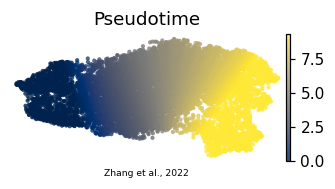

In [9]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')